<a href="https://colab.research.google.com/github/ysf-dmk/Bank-Marketing/blob/main/Model_Comparison_and_Error_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bank Marketing – Machine Learning Project

## Week 3: Model Comparison and Error Analysis

**Author:** Chaima Garoui

### Objective

The objective of this notebook is to compare the
performance of the different classification models,
analyze prediction errors and interpret the results
in the context of bank marketing.

All models will be compared using a consistent
evaluation protocol, without using the independent
test set for model selection or hyperparameter tuning.

In [55]:
!git clone https://github.com/ysf-dmk/Bank-Marketing.git

Cloning into 'Bank-Marketing'...
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (74/74), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 74 (delta 38), reused 60 (delta 29), pack-reused 0 (from 0)
Receiving objects: 100% (74/74), 1.44 MiB | 12.62 MiB/s, done.
Resolving deltas: 100% (38/38), done.


In [56]:
%cd /content/Bank-Marketing
!ls

/content/Bank-Marketing
AI_AUDIT.md		  Baseline_Model.ipynb		PROMPT_LOG.md
bank-additional-full.csv  Cleaning_Preprocessing.ipynb	README.md
bank_clean.csv		  CONTRIBUTIONS.md		requirements.txt
Bank-Marketing		  EDA_and_Data_Quality.ipynb	src


In [57]:
!ls src

data_prep.py  __pycache__


## 1. Data Preparation and Experimental Setup

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_prep import (
    load_raw,
    clean,
    split,
    build_preprocessor
)

print("Libraries and preprocessing module imported successfully.")

Libraries and preprocessing module imported successfully.


In [59]:
df_raw = load_raw("bank-additional-full.csv")
df_clean = clean(df_raw)

print("Original dataset:", df_raw.shape)
print("Cleaned dataset:", df_clean.shape)
print("Positive class proportion:", df_clean["y"].mean())

Original dataset: (41188, 21)
Cleaned dataset: (41176, 21)
Positive class proportion: 0.11266271614532737


In [60]:
X_train, X_val, X_test, y_train, y_val, y_test = split(df_clean)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (24705, 20)
Validation set: (8235, 20)
Test set: (8236, 20)


### Interpretation

The original dataset contains 41,188 observations. After applying the shared cleaning function, 12 duplicate observations were removed, leaving 41,176 observations.

The positive class represents approximately 11.27% of the dataset, confirming that the target variable is imbalanced.

The dataset was divided into training (60%), validation (20%) and test (20%) sets using the shared splitting function. Reusing the same data preparation process ensures consistency across team members and allows a fair comparison between models.

The test set will remain unused during model selection and hyperparameter optimization.

In [61]:
print("Input features:")
print(X_train.columns.tolist())

assert "duration" not in X_train.columns, "Data leakage detected!"

print("\nPositive class proportions:")
print(f"Training:   {y_train.mean():.2%}")
print(f"Validation: {y_val.mean():.2%}")
print(f"Test:       {y_test.mean():.2%}")

print("\nData leakage feature check passed.")

Input features:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_contacted_before']

Positive class proportions:
Training:   11.26%
Validation: 11.27%
Test:       11.27%

Data leakage feature check passed.


## 2. Model Evaluation Framework

In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


### Interpretation

The positive class proportions are almost identical across the training (11.26%), validation (11.27%) and test (11.27%) sets. This confirms that the stratified splitting method preserves the original class distribution.

The duration variable has also been excluded from the input features because the call duration is only known after the call has ended. Removing this variable prevents this specific source of data leakage and makes the prediction scenario more realistic.

### 2.1. Reusable Model Evaluation Function

In [63]:
def evaluate_model(model, X, y, model_name, threshold=0.5):

    # Get the probability of subscription
    y_prob = model.predict_proba(X)[:, 1]

    # Convert probabilities into binary predictions
    y_pred = (y_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    results = {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred, zero_division=0),
        "F1-score": f1_score(y, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, y_prob),
        "Average Precision": average_precision_score(y, y_prob)
    }

    return results, y_pred, y_prob


print("Model evaluation function created successfully.")

Model evaluation function created successfully.


## 3. Reference Baseline Evaluation

### 3.1. Dummy Classifier

In [64]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(
    strategy="prior",
    random_state=42
)

dummy_model.fit(X_train, y_train)

print("Dummy Classifier trained successfully.")

Dummy Classifier trained successfully.


In [65]:
dummy_results, dummy_pred, dummy_prob = evaluate_model(
    model=dummy_model,
    X=X_val,
    y=y_val,
    model_name="Dummy Classifier",
    threshold=0.5
)

pd.DataFrame([dummy_results]).round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Dummy Classifier,0.5,0.8873,0.0,0.0,0.0,0.5,0.1127


In [66]:
all_results = [dummy_results]

comparison_df = pd.DataFrame(all_results)

comparison_df.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Dummy Classifier,0.5,0.8873,0.0,0.0,0.0,0.5,0.1127


### Interpretation

The Dummy Classifier achieves an accuracy of 88.73%, which may initially seem high. However, its precision, recall and F1-score are all equal to zero because it predicts every customer as a non-subscriber.

The ROC-AUC of 0.5 confirms that the model has no ability to distinguish between subscribers and non-subscribers. The Average Precision of 0.1127 corresponds to the proportion of the positive class.

These results demonstrate why accuracy alone is not sufficient when evaluating an imbalanced dataset. This classifier will serve as a reference benchmark for comparing more advanced machine learning models.

## 4. Confusion Matrix and Error Analysis

### 4.1. Reusable Confusion Matrix Function

## 4. Confusion Matrix and Error Analysis

### 4.1. Reusable Confusion Matrix Function

In [67]:
def plot_confusion_matrix(y_true, y_pred, model_name):

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Subscription", "Subscription"],
        yticklabels=["No Subscription", "Subscription"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

    return cm

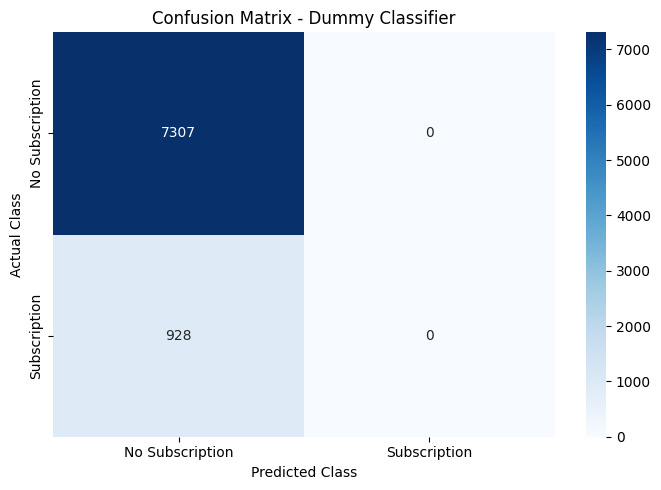

In [68]:
dummy_cm = plot_confusion_matrix(
    y_val,
    dummy_pred,
    "Dummy Classifier"
)

In [69]:
tn, fp, fn, tp = dummy_cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 7307
False Positives: 0
False Negatives: 928
True Positives: 0


### Confusion Matrix Interpretation

The confusion matrix shows that the Dummy Classifier correctly identifies 7,307 non-subscribers but fails to identify any of the 928 actual subscribers.

Although the model achieves high accuracy, it is not useful for the bank's marketing objective because it cannot identify potential customers who are likely to subscribe to a term deposit.

From a business perspective, the 928 false negatives represent missed marketing opportunities. More advanced models should reduce the number of false negatives while maintaining a reasonable number of false positives.

**Step 7 — Logistic Regression baseline**

In [70]:
!git fetch origin
!git branch -r
!ls

remote: Enumerating objects: 20, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 14 (delta 10), reused 9 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (14/14), 288.18 KiB | 5.44 MiB/s, done.
From https://github.com/ysf-dmk/Bank-Marketing
   dcc230e..2e88922  main       -> origin/main
 * [new branch]      mariem/temporal-baseline -> origin/mariem/temporal-baseline
  origin/HEAD -> origin/main
  origin/main
  origin/mariem/temporal-baseline
  origin/mariem/week2-baseline
AI_AUDIT.md		  Baseline_Model.ipynb		PROMPT_LOG.md
bank-additional-full.csv  Cleaning_Preprocessing.ipynb	README.md
bank_clean.csv		  CONTRIBUTIONS.md		requirements.txt
Bank-Marketing		  EDA_and_Data_Quality.ipynb	src


In [71]:
!find . -iname "*baseline*"

./Baseline_Model.ipynb
./Bank-Marketing/Baseline_Model.ipynb
./.git/logs/refs/remotes/origin/mariem/temporal-baseline
./.git/refs/remotes/origin/mariem/temporal-baseline


Inspect Mariem's Logistic Regression configuration

In [72]:
import json

with open("Baseline_Model.ipynb", "r", encoding="utf-8") as f:
    baseline_notebook = json.load(f)

for i, cell in enumerate(baseline_notebook["cells"]):

    if cell["cell_type"] == "code":

        source = "".join(cell["source"])

        if any(keyword in source for keyword in [
            "LogisticRegression",
            "Pipeline(",
            "class_weight",
            "threshold",
            "build_preprocessor"
        ]):
            print(f"\n--- Cell {i} ---\n")
            print(source)


--- Cell 2 ---

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve
)

from src.data_prep import split, build_preprocessor

RANDOM_STATE = 42

print("Libraries imported successfully.")

--- Cell 11 ---

dummy_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", DummyClassifier(strategy="prior"))
])

dummy_pipeline.fit(X_train, y_train)

print("Dummy Classifier trained successfully.")

--- Cell 15 ---

lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        rando

In [73]:
import json

with open("Baseline_Model.ipynb", "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        print(f"\n--- Cell {i} ---\n")
        print("".join(cell["source"]))


--- Cell 0 ---

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment ready!")

--- Cell 2 ---

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve
)

from src.data_prep import split, build_preprocessor

RANDOM_STATE = 42

print("Libraries imported successfully.")

--- Cell 4 ---

df = pd.read_csv("bank_clean.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

--- Cell 5 ---

assert len(df) == 41176, "Unexpected number of rows"
assert df.shape[1] == 

In [74]:
df_mariem = pd.read_csv("bank_clean.csv")

pd.testing.assert_frame_equal(
    df_clean.reset_index(drop=True),
    df_mariem.reset_index(drop=True),
    check_dtype=False
)

print("Dataset consistency check PASSED.")

Dataset consistency check PASSED.


### 4.2. Logistic Regression Baseline

In [75]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression baseline reproduced successfully.")

Logistic Regression baseline reproduced successfully.


In [76]:
lr_results, lr_pred, lr_prob = evaluate_model(
    model=lr_pipeline,
    X=X_val,
    y=y_val,
    model_name="Logistic Regression (Default)",
    threshold=0.5
)

all_results = [dummy_results, lr_results]

comparison_df = pd.DataFrame(all_results)

comparison_df.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Dummy Classifier,0.5,0.8873,0.0000,0.0000,0.000,0.5000,0.1127
1,Logistic Regression (Default),0.5,0.9012,0.6926,0.2209,0.335,0.8081,0.4742


### Model Comparison Interpretation

Logistic Regression performs better than the Dummy Classifier across all evaluation metrics. Although accuracy only increases from 88.73% to 90.12%, the other metrics show a more meaningful improvement.

The model achieves a precision of 69.26%, meaning that most customers predicted as subscribers actually subscribe. However, the recall of 22.09% remains relatively low, indicating that many actual subscribers are still missed.

The ROC-AUC of 0.8081 demonstrates a good ability to distinguish between the two classes. Average Precision also increases from 0.1127 to 0.4742, showing a significant improvement in identifying the minority class.

The main limitation of Logistic Regression at the default threshold is its low recall. Threshold optimization may help identify more potential subscribers.

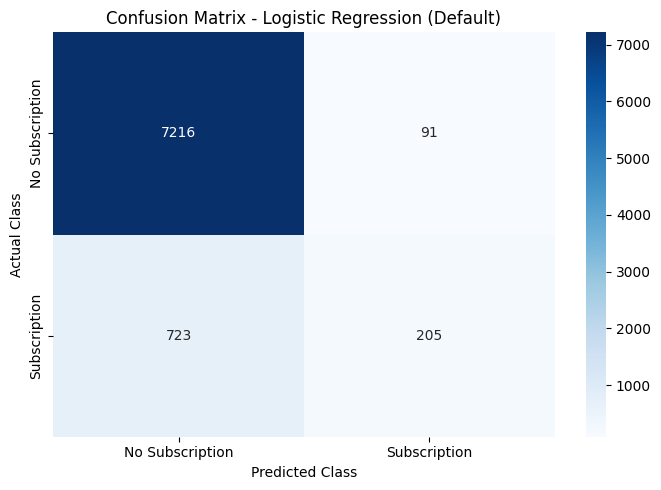

In [77]:
lr_cm = plot_confusion_matrix(
    y_val,
    lr_pred,
    "Logistic Regression (Default)"
)

### Confusion Matrix Interpretation

Logistic Regression correctly identifies 205 actual subscribers, compared to zero for the Dummy Classifier. It also correctly classifies 7,216 non-subscribers.

However, the model produces 723 false negatives and 91 false positives. This means that approximately 77.91% of actual subscribers remain undetected.

From a business perspective, false negatives represent potential missed subscription opportunities, while false positives may lead to unnecessary marketing calls and additional operational costs.

Finding a better balance between these two types of errors is therefore important for the bank's marketing strategy.

**Threshold optimization**

### 4.3. Logistic Regression with Optimized Threshold

In [78]:
precision, recall, thresholds = precision_recall_curve(
    y_val, lr_prob
)

f1_scores = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(precision[:-1]),
    where=(precision[:-1] + recall[:-1]) != 0
)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Default threshold: 0.5000")
print(f"Optimal threshold: {best_threshold:.4f}")
print(f"Best F1-score: {f1_scores[best_idx]:.4f}")

Default threshold: 0.5000
Optimal threshold: 0.2385
Best F1-score: 0.5156


In [79]:
lr_opt_results, lr_opt_pred, lr_opt_prob = evaluate_model(
    model=lr_pipeline,
    X=X_val,
    y=y_val,
    model_name="Logistic Regression (Optimized Threshold)",
    threshold=best_threshold
)

all_results = [
    dummy_results,
    lr_results,
    lr_opt_results
]

comparison_df = pd.DataFrame(all_results)

comparison_df.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Dummy Classifier,0.5000,0.8873,0.0000,0.0000,0.0000,0.5000,0.1127
1,Logistic Regression (Default),0.5000,0.9012,0.6926,0.2209,0.3350,0.8081,0.4742
2,Logistic Regression (Optimized Threshold),0.2385,0.8884,0.5046,0.5269,0.5156,0.8081,0.4742


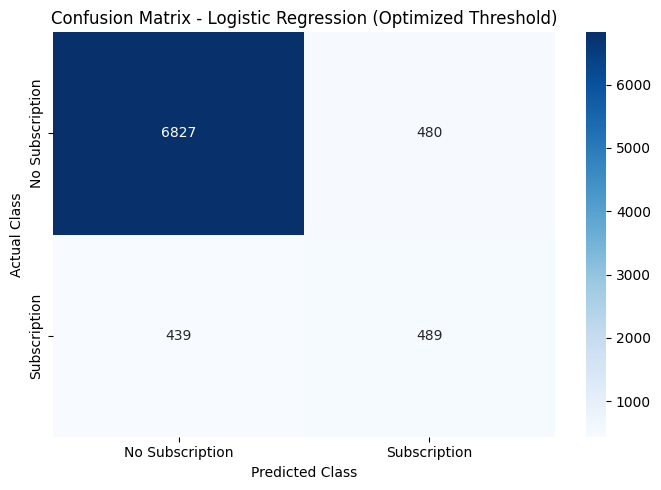

In [80]:
lr_opt_cm = plot_confusion_matrix(
    y_val,
    lr_opt_pred,
    "Logistic Regression (Optimized Threshold)"
)

### Threshold Optimization Interpretation

Reducing the classification threshold from 0.5 to 0.2385 increases recall from 22.09% to 52.69%. The F1-score also improves from 0.3350 to 0.5156, indicating a better balance between precision and recall.

However, precision decreases from 69.26% to 50.46%, and accuracy slightly decreases from 90.12% to 88.84%. This shows the trade-off between identifying more potential subscribers and generating more incorrect positive predictions.

ROC-AUC and Average Precision remain unchanged because threshold optimization modifies the final classification decisions rather than the predicted probabilities.

Since the threshold was selected using the validation set, these improvements must be confirmed on the independent test set during the final evaluation.

**Business-oriented error analysis**

## 5. Business-Oriented Error Analysis

### 5.1. Comparison of Prediction Errors

In [81]:
def summarize_errors(y_true, y_pred, model_name):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Model": model_name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Customers Targeted": tp + fp,
        "Missed Subscriber Rate (%)": 100 * fn / (fn + tp),
        "False Positive Rate (%)": 100 * fp / (fp + tn)
    }


error_analysis_df = pd.DataFrame([
    summarize_errors(y_val, dummy_pred, "Dummy Classifier"),
    summarize_errors(y_val, lr_pred, "Logistic Regression (Default)"),
    summarize_errors(y_val, lr_opt_pred, "Logistic Regression (Optimized)")
])

error_analysis_df.round(2)

,Model,True Negatives,False Positives,False Negatives,True Positives,Customers Targeted,Missed Subscriber Rate (%),False Positive Rate (%)
0,Dummy Classifier,7307,0,928,0,0,100.00,0.00
1,Logistic Regression (Default),7216,91,723,205,296,77.91,1.25
2,Logistic Regression (Optimized),6827,480,439,489,969,47.31,6.57


### Business-Oriented Error Analysis Interpretation

The optimized Logistic Regression model increases the number of targeted customers from 296 to 969. It identifies 284 additional subscribers but also generates 389 additional false positives.

The missed subscriber rate decreases from 77.91% to 47.31%, which is an important improvement for the bank's marketing objective. However, the false positive rate increases from 1.25% to 6.57%.

These results highlight a business trade-off. Targeting more customers can help identify more potential subscribers, but it also requires additional marketing resources. The preferred model should therefore depend on the bank's budget and campaign objectives rather than accuracy alone.

### 5.2. Visualization of Prediction Errors

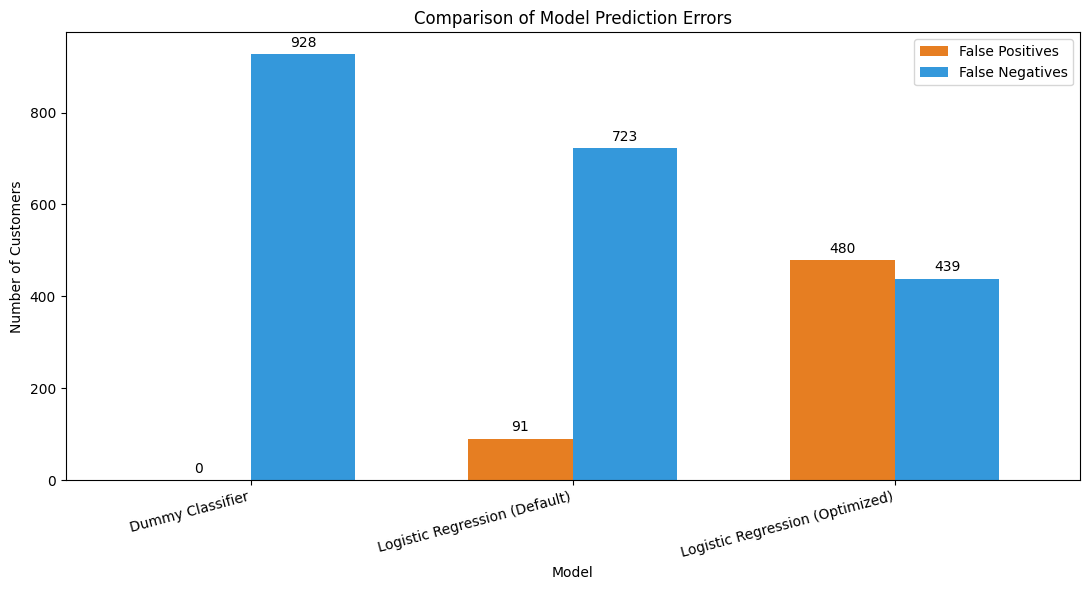

In [82]:
error_plot = error_analysis_df.set_index("Model")[
    ["False Positives", "False Negatives"]
]

ax = error_plot.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#E67E22", "#3498DB"],
    width=0.65
)

plt.title("Comparison of Model Prediction Errors")
plt.ylabel("Number of Customers")
plt.xlabel("Model")
plt.xticks(rotation=15, ha="right")

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.legend()
plt.tight_layout()
plt.show()

### Prediction Error Visualization Interpretation

The graph shows how prediction errors change across the three classification approaches. The Dummy Classifier produces the highest number of false negatives (928) because it predicts every customer as a non-subscriber.

Logistic Regression with the default threshold reduces false negatives to 723 while generating only 91 false positives.

After threshold optimization, false negatives decrease further to 439, but false positives increase to 480.

This visualization highlights the importance of balancing both types of errors according to the bank's marketing objectives and available resources.

Business cost sensitivity analysis

### 5.3. Business Cost Sensitivity Analysis

This analysis investigates how different assumptions
about misclassification costs affect model selection.

In [83]:
fp_cost = 1
fn_costs = [0.25, 0.5, 1, 2, 5, 10]

cost_results = []

for fn_cost in fn_costs:

    for _, row in error_analysis_df.iterrows():

        total_cost = (
            row["False Positives"] * fp_cost
            + row["False Negatives"] * fn_cost
        )

        cost_results.append({
            "Model": row["Model"],
            "FP Cost": fp_cost,
            "FN Cost": fn_cost,
            "Total Cost": total_cost
        })

cost_df = pd.DataFrame(cost_results)

cost_comparison = cost_df.pivot(
    index="FN Cost",
    columns="Model",
    values="Total Cost"
)

cost_comparison.round(2)

Model,Dummy Classifier,Logistic Regression (Default),Logistic Regression (Optimized)
FN Cost,,,
0.25,232.0,271.75,589.75
0.50,464.0,452.50,699.50
1.00,928.0,814.00,919.00
2.00,1856.0,1537.00,1358.00
5.00,4640.0,3706.00,2675.00
10.00,9280.0,7321.00,4870.00


### Business Cost Sensitivity Interpretation

The results show that the preferred classification approach depends on the relative cost of false positives and false negatives.

When the cost of missing a subscriber is very low (€0.25), the Dummy Classifier produces the lowest estimated cost. When the cost increases to €0.50 or €1, Logistic Regression with the default threshold becomes preferable.

However, when the false negative cost reaches €2 or more in the tested scenarios, Logistic Regression with the optimized threshold achieves the lowest estimated cost.

For example, when a false negative costs €5, the optimized approach reduces the estimated cost from €3,706 to €2,675 compared to the default threshold, representing a reduction of approximately 27.82%.

These results demonstrate that model selection should consider business objectives and the relative consequences of prediction errors, rather than relying exclusively on statistical performance.

The costs used in this analysis are hypothetical and do not represent actual financial data from the bank.

### 5.4. Break-Even Point Analysis

In [84]:
errors = error_analysis_df.set_index("Model")

dummy = errors.loc["Dummy Classifier"]
default = errors.loc["Logistic Regression (Default)"]
optimized = errors.loc["Logistic Regression (Optimized)"]

break_even_1 = (
    (default["False Positives"] - dummy["False Positives"])
    * fp_cost
    / (dummy["False Negatives"] - default["False Negatives"])
)

break_even_2 = (
    (optimized["False Positives"] - default["False Positives"])
    * fp_cost
    / (default["False Negatives"] - optimized["False Negatives"])
)

print(f"Dummy vs Default LR: €{break_even_1:.4f}")
print(f"Default vs Optimized LR: €{break_even_2:.4f}")

Dummy vs Default LR: €0.4439
Default vs Optimized LR: €1.3697


### Break-Even Point Interpretation

The break-even analysis identifies two critical cost thresholds.

When the cost of a false negative is below €0.4439, the Dummy Classifier has the lowest estimated misclassification cost.

Between €0.4439 and €1.3697, Logistic Regression with the default threshold is the most cost-effective approach.

Above €1.3697, Logistic Regression with the optimized threshold becomes preferable because the benefit of reducing missed subscribers outweighs the additional cost of false positives.

These findings demonstrate that the preferred classification strategy depends on the relative costs of prediction errors. However, these conclusions are based on hypothetical costs and validation-set results.

### 5.5. Cost Sensitivity Visualization

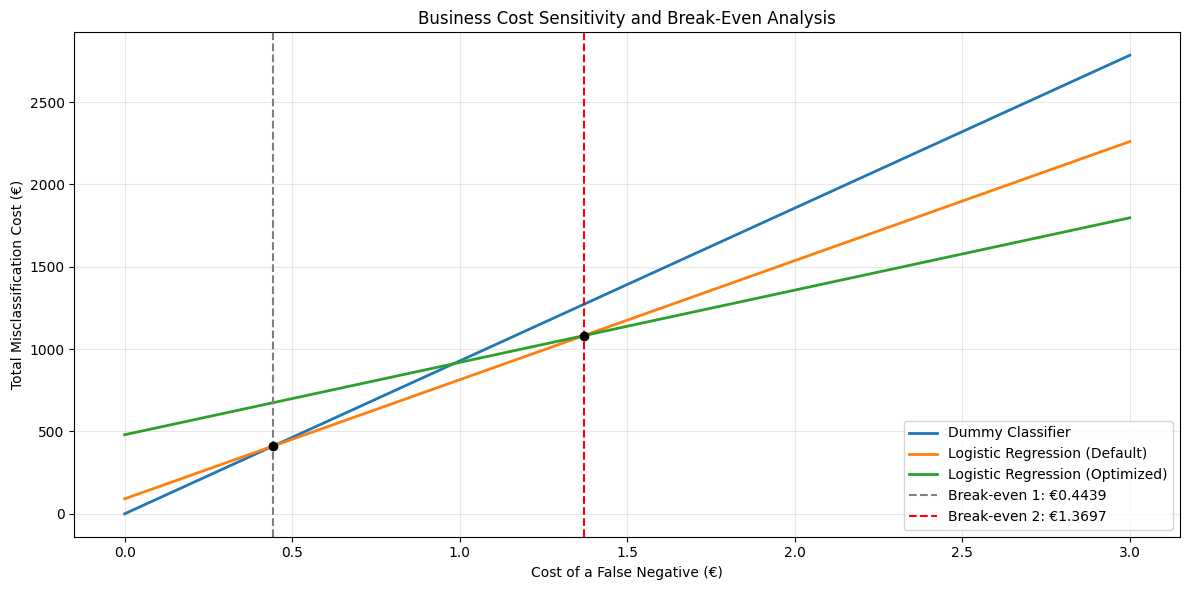

In [85]:
fn_cost_range = np.linspace(0, 3, 300)

plt.figure(figsize=(12, 6))

for _, row in error_analysis_df.iterrows():

    total_cost = (
        row["False Positives"] * fp_cost
        + row["False Negatives"] * fn_cost_range
    )

    plt.plot(
        fn_cost_range,
        total_cost,
        label=row["Model"],
        linewidth=2
    )

plt.axvline(
    break_even_1,
    color="gray",
    linestyle="--",
    label=f"Break-even 1: €{break_even_1:.4f}"
)

plt.axvline(
    break_even_2,
    color="red",
    linestyle="--",
    label=f"Break-even 2: €{break_even_2:.4f}"
)

plt.scatter(
    break_even_1,
    dummy["False Negatives"] * break_even_1,
    color="black",
    zorder=5
)

plt.scatter(
    break_even_2,
    default["False Positives"] * fp_cost
    + default["False Negatives"] * break_even_2,
    color="black",
    zorder=5
)

plt.title("Business Cost Sensitivity and Break-Even Analysis")
plt.xlabel("Cost of a False Negative (€)")
plt.ylabel("Total Misclassification Cost (€)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Cost Sensitivity Visualization Interpretation

The graph illustrates how the total misclassification cost changes as the cost of a false negative increases.

The Dummy Classifier has the steepest curve because it misses all 928 actual subscribers. Logistic Regression with the optimized threshold has the lowest slope because it produces fewer false negatives.

The two highlighted break-even points identify where the preferred classification approach changes. Beyond €1.3697, the optimized threshold provides the lowest estimated cost among the three approaches.

This analysis demonstrates that the best classification strategy depends not only on predictive performance but also on the business consequences of prediction errors.

**Customer subgroup error analysis**

## 6. Customer Subgroup Error Analysis

### 6.1. Preparation of the Error Analysis Dataset

In [86]:
analysis_df = X_val.copy().reset_index(drop=True)

analysis_df["Actual"] = np.asarray(y_val)
analysis_df["Predicted_Default"] = lr_pred
analysis_df["Predicted_Optimized"] = lr_opt_pred
analysis_df["Subscription_Probability"] = lr_prob

analysis_df["False_Negative"] = (
    (analysis_df["Actual"] == 1) &
    (analysis_df["Predicted_Optimized"] == 0)
).astype(int)

analysis_df["False_Positive"] = (
    (analysis_df["Actual"] == 0) &
    (analysis_df["Predicted_Optimized"] == 1)
).astype(int)

print("Error analysis dataset:", analysis_df.shape)
print("False negatives:", analysis_df["False_Negative"].sum())
print("False positives:", analysis_df["False_Positive"].sum())

analysis_df.head()

Error analysis dataset: (8235, 26)
False negatives: 439
False positives: 480


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,cons.conf.idx,euribor3m,nr.employed,was_contacted_before,Actual,Predicted_Default,Predicted_Optimized,Subscription_Probability,False_Negative,False_Positive
0,30,blue-collar,married,basic.9y,no,no,no,telephone,may,wed,...,-36.4,4.858,5191.0,0,0,0,0,0.037077,0,0
1,37,technician,divorced,professional.course,no,no,no,cellular,may,mon,...,-46.2,1.299,5099.1,0,0,0,0,0.051243,0,0
2,33,services,married,professional.course,no,yes,no,cellular,aug,thu,...,-36.1,4.962,5228.1,0,0,0,0,0.050165,0,0
3,28,admin.,single,university.degree,no,yes,no,telephone,may,mon,...,-36.4,4.858,5191.0,0,0,0,0,0.036205,0,0
4,35,management,married,university.degree,no,no,yes,telephone,aug,mon,...,-36.1,4.965,5228.1,0,0,0,0,0.020086,0,0


Error analysis by age group

### 6.2. Model Performance by Age Group

In [87]:
analysis_df["Age_Group"] = pd.cut(
    analysis_df["age"],
    bins=[0, 24, 34, 44, 54, 64, np.inf],
    labels=["Under 25", "25-34", "35-44",
            "45-54", "55-64", "65+"]
)

analysis_df["Age_Group"].value_counts().sort_index()

,count
Age_Group,
Under 25,213
25-34,2705
35-44,2723
45-54,1758
55-64,710
65+,126


In [88]:
def evaluate_subgroups(data, group_column):

    results = []

    for group, subset in data.groupby(
        group_column, observed=True
    ):

        tn, fp, fn, tp = confusion_matrix(
            subset["Actual"],
            subset["Predicted_Optimized"],
            labels=[0, 1]
        ).ravel()

        results.append({
            "Group": group,
            "Sample Size": len(subset),
            "Actual Subscribers": tp + fn,
            "True Positives": tp,
            "False Positives": fp,
            "False Negatives": fn,
            "Recall (%)": 100 * tp / (tp + fn)
                if tp + fn > 0 else np.nan,
            "False Negative Rate (%)": 100 * fn / (tp + fn)
                if tp + fn > 0 else np.nan,
            "False Positive Rate (%)": 100 * fp / (fp + tn)
                if fp + tn > 0 else np.nan,
            "Precision (%)": 100 * tp / (tp + fp)
                if tp + fp > 0 else np.nan
        })

    return pd.DataFrame(results)

In [89]:
age_analysis = evaluate_subgroups(
    analysis_df,
    "Age_Group"
)

age_analysis.round(2)

,Group,Sample Size,Actual Subscribers,True Positives,False Positives,False Negatives,Recall (%),False Negative Rate (%),False Positive Rate (%),Precision (%)
0,Under 25,213,58,44,37,14,75.86,24.14,23.87,54.32
1,25-34,2705,351,175,177,176,49.86,50.14,7.52,49.72
2,35-44,2723,228,98,91,130,42.98,57.02,3.65,51.85
3,45-54,1758,141,71,68,70,50.35,49.65,4.21,51.08
4,55-64,710,89,46,58,43,51.69,48.31,9.34,44.23
5,65+,126,61,55,49,6,90.16,9.84,75.38,52.88


### Age Subgroup Analysis Interpretation

The results show that the optimized Logistic Regression model does not perform equally across all age groups.

Customers aged 65 and above have the highest recall at 90.16%. However, this group also has a false positive rate of 75.38%, suggesting that the model frequently predicts subscriptions for older customers who do not actually subscribe.

The 35–44 age group has the lowest recall at 42.98%, meaning that more than half of the actual subscribers in this group are missed.

Customers under 25 also have relatively high recall, although their false positive rate is higher than that of most middle-aged groups.

These differences highlight the importance of evaluating model performance at the subgroup level rather than relying only on overall metrics. However, the smaller sample sizes of the youngest and oldest groups require careful interpretation. Further statistical analysis is needed before drawing conclusions about potential age-related bias.

### 6.3. Age Group Performance Visualization

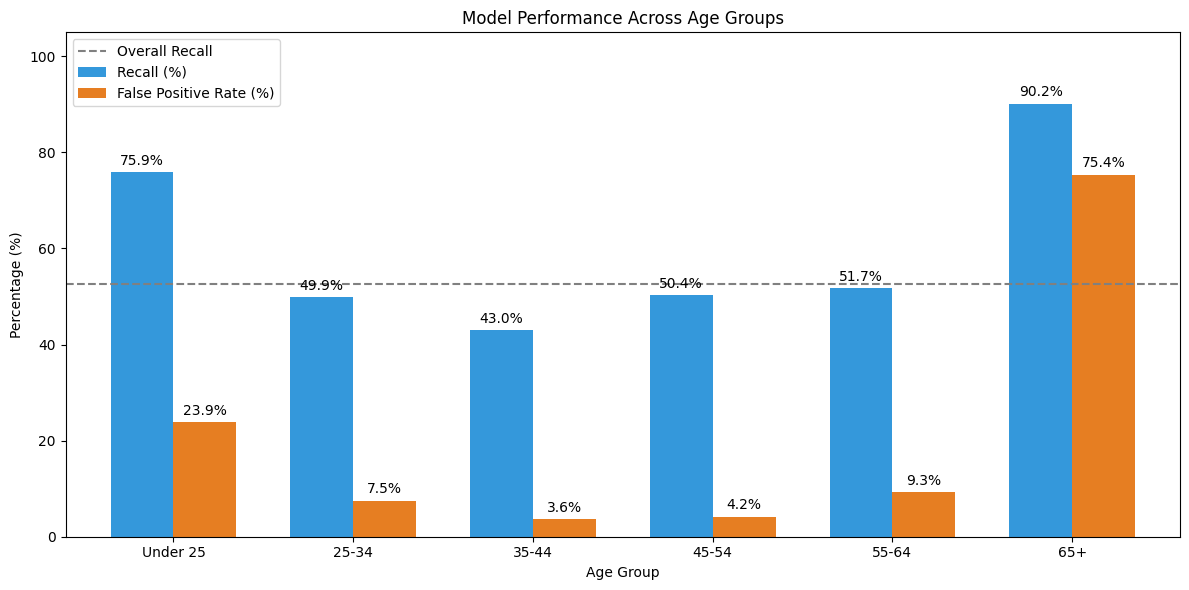

In [90]:
age_plot = age_analysis.set_index("Group")[
    ["Recall (%)", "False Positive Rate (%)"]
]

ax = age_plot.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#3498DB", "#E67E22"],
    width=0.7
)

plt.axhline(
    y=recall_score(y_val, lr_opt_pred) * 100,
    color="gray",
    linestyle="--",
    label="Overall Recall"
)

plt.title("Model Performance Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Percentage (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.legend()
plt.tight_layout()
plt.show()

### Age Group Performance Visualization Interpretation

The visualization shows clear differences in model performance across age groups. Customers under 25 and those aged 65 and above achieve recall values higher than the overall recall of 52.69%.

However, the 65+ group also has a particularly high false positive rate of 75.38%. This indicates that the model identifies most actual subscribers in this group but also incorrectly classifies many non-subscribers.

The 35–44 age group has the lowest recall, suggesting that the model struggles to identify potential subscribers within this category.

These results highlight the importance of subgroup evaluation. However, differences in sample sizes and customer characteristics must be considered before concluding that the model exhibits age-related bias.

Error analysis by occupation

### 6.4. Model Performance by Occupation

In [91]:
job_analysis = evaluate_subgroups(
    analysis_df,
    "job"
)

job_analysis = job_analysis.sort_values(
    "Recall (%)",
    ascending=False
).reset_index(drop=True)

job_analysis.round(2)

,Group,Sample Size,Actual Subscribers,True Positives,False Positives,False Negatives,Recall (%),False Negative Rate (%),False Positive Rate (%),Precision (%)
0,unknown,55,5,5,1,0,100.00,0.00,2.00,83.33
1,student,176,57,48,46,9,84.21,15.79,38.66,51.06
2,retired,338,80,64,70,16,80.00,20.00,27.13,47.76
3,unemployed,192,27,17,17,10,62.96,37.04,10.30,50.00
4,housemaid,221,16,10,9,6,62.50,37.50,4.39,52.63
5,admin.,2093,299,181,145,118,60.54,39.46,8.08,55.52
6,management,642,60,32,44,28,53.33,46.67,7.56,42.11
7,technician,1296,138,66,64,72,47.83,52.17,5.53,50.77
8,self-employed,287,36,12,13,24,33.33,66.67,5.18,48.00
9,services,780,65,19,25,46,29.23,70.77,3.50,43.18


### Occupation Subgroup Analysis Interpretation

The results reveal important differences in model performance across occupational groups. Students and retired customers achieve relatively high recall, indicating that the model successfully identifies a large proportion of actual subscribers in these categories. However, their false positive rates are also relatively high.

Entrepreneurs and blue-collar workers have considerably lower recall, meaning that many potential subscribers within these groups remain undetected.

The unknown occupation category achieves 100% recall, but this result is based on only five actual subscribers and should therefore be interpreted with caution.

Overall, these findings show that aggregate performance metrics can hide important differences between customer groups. Further statistical analysis is necessary to assess the reliability of these differences.

### 6.5. Occupation Performance Visualization

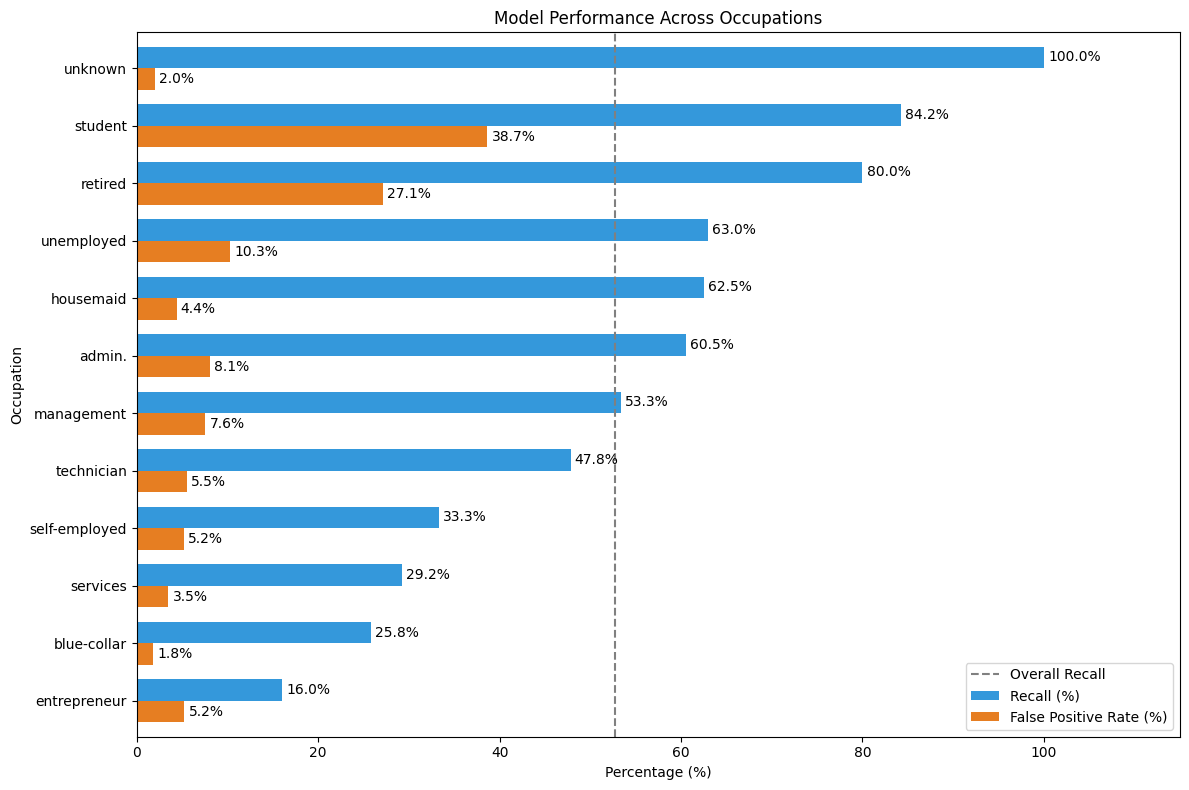

In [92]:
job_plot = job_analysis.set_index("Group")[
    ["Recall (%)", "False Positive Rate (%)"]
]

ax = job_plot.plot(
    kind="barh",
    figsize=(12, 8),
    color=["#3498DB", "#E67E22"],
    width=0.75
)

ax.invert_yaxis()

plt.axvline(
    x=recall_score(y_val, lr_opt_pred) * 100,
    color="gray",
    linestyle="--",
    label="Overall Recall"
)

plt.title("Model Performance Across Occupations")
plt.xlabel("Percentage (%)")
plt.ylabel("Occupation")
plt.xlim(0, 115)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.legend()
plt.tight_layout()
plt.show()

### Occupation Performance Visualization Interpretation

The visualization shows that model performance varies considerably across occupations. Students and retired customers achieve recall values well above the overall recall of 52.69%, but they also have relatively high false positive rates.

In contrast, entrepreneurs, blue-collar workers and customers working in services have low recall values. This means that the model fails to identify a large proportion of actual subscribers in these categories.

The unknown occupation category achieves perfect recall, but its small number of actual subscribers makes this result less reliable.

These differences demonstrate why subgroup analysis is important when evaluating a classification model. Overall performance alone may hide weaknesses within specific customer categories.

Error analysis by education level

### 6.6. Model Performance by Education Level

In [93]:
education_analysis = evaluate_subgroups(
    analysis_df,
    "education"
)

education_analysis = education_analysis.sort_values(
    "Recall (%)",
    ascending=False
).reset_index(drop=True)

education_analysis.round(2)

,Group,Sample Size,Actual Subscribers,True Positives,False Positives,False Negatives,Recall (%),False Negative Rate (%),False Positive Rate (%),Precision (%)
0,unknown,342,41,27,29,14,65.85,34.15,9.63,48.21
1,university.degree,2479,341,203,224,138,59.53,40.47,10.48,47.54
2,professional.course,1035,123,67,50,56,54.47,45.53,5.48,57.26
3,basic.4y,862,82,42,35,40,51.22,48.78,4.49,54.55
4,high.school,1888,210,104,95,106,49.52,50.48,5.66,52.26
5,basic.6y,453,36,15,14,21,41.67,58.33,3.36,51.72
6,basic.9y,1174,95,31,33,64,32.63,67.37,3.06,48.44
7,illiterate,2,0,0,0,0,NaN,NaN,0.00,NaN


### Education Subgroup Analysis Interpretation

The results show that model performance varies across education levels. Customers with unknown education levels and university degrees achieve recall values above the overall recall of 52.69%.

In contrast, customers in the basic.9y category have the lowest measurable recall at 32.63%, meaning that approximately two-thirds of actual subscribers in this group are missed.

The illiterate category contains only two observations and no actual subscribers in the validation set. Therefore, recall and precision cannot be calculated for this category. This confirms the small sample size limitation identified during the exploratory data analysis.

These results highlight the importance of considering subgroup representation and statistical uncertainty when evaluating model performance.

### 6.7. Education Level Performance Visualization

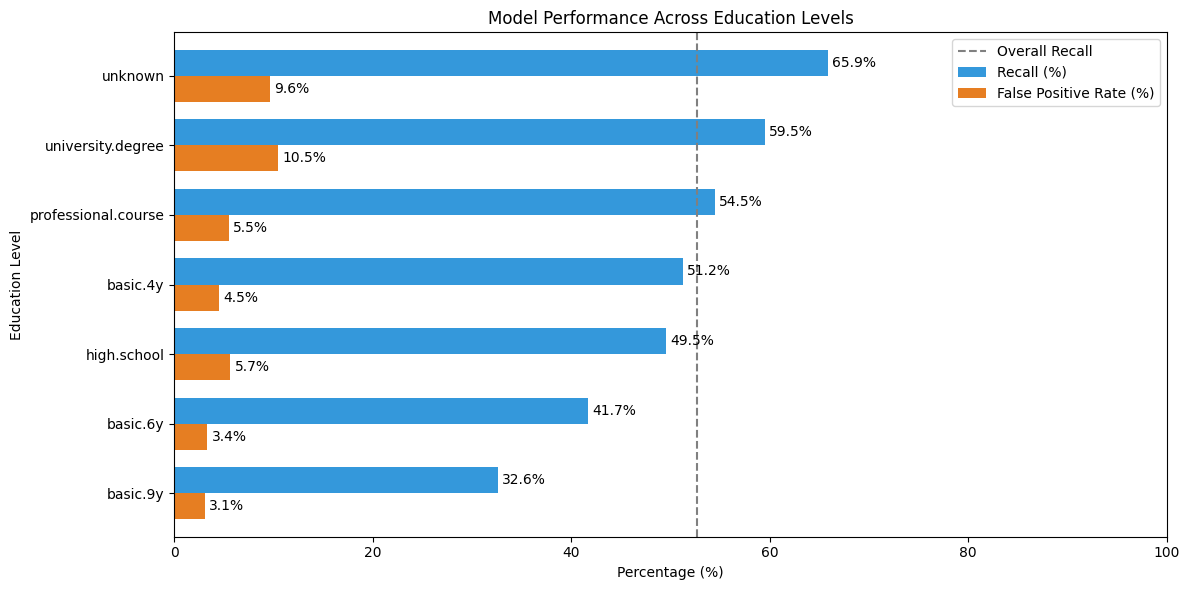

In [94]:
education_plot = education_analysis.dropna(
    subset=["Recall (%)"]
).set_index("Group")[
    ["Recall (%)", "False Positive Rate (%)"]
]

ax = education_plot.plot(
    kind="barh",
    figsize=(12, 6),
    color=["#3498DB", "#E67E22"],
    width=0.75
)

ax.invert_yaxis()

plt.axvline(
    x=recall_score(y_val, lr_opt_pred) * 100,
    color="gray",
    linestyle="--",
    label="Overall Recall"
)

plt.title("Model Performance Across Education Levels")
plt.xlabel("Percentage (%)")
plt.ylabel("Education Level")
plt.xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.legend()
plt.tight_layout()
plt.show()

### Education Performance Visualization Interpretation

The visualization shows that customers with unknown education levels, university degrees and professional courses achieve recall values above the overall recall of 52.69%.

In contrast, customers in the basic.9y and basic.6y categories have lower recall, indicating that the model misses a larger proportion of actual subscribers in these groups.

University graduates have the highest false positive rate among the education categories displayed.

The illiterate category is excluded from the visualization because recall is undefined due to the absence of actual subscribers in the validation set.

These differences highlight the need to consider subgroup performance and sample sizes when evaluating the model.

Error analysis by marital status

### 6.8. Model Performance by Marital Status

In [95]:
marital_analysis = evaluate_subgroups(
    analysis_df,
    "marital"
)

marital_analysis = marital_analysis.sort_values(
    "Recall (%)",
    ascending=False
).reset_index(drop=True)

marital_analysis.round(2)

,Group,Sample Size,Actual Subscribers,True Positives,False Positives,False Negatives,Recall (%),False Negative Rate (%),False Positive Rate (%),Precision (%)
0,single,2270,360,216,192,144,60.00,40.00,10.05,52.94
1,divorced,925,97,47,37,50,48.45,51.55,4.47,55.95
2,married,5025,471,226,249,245,47.98,52.02,5.47,47.58
3,unknown,15,0,0,2,0,NaN,NaN,13.33,0.00


### Marital Status Subgroup Analysis Interpretation

The results show that the model identifies single subscribers more effectively, achieving a recall of 60%, compared to 48.45% for divorced customers and 47.98% for married customers.

Married customers account for the largest number of false negatives, with 245 missed subscribers. This is partly explained by their larger representation in the validation dataset.

The unknown marital status category contains only 15 observations and no actual subscribers. Therefore, recall cannot be calculated, and its false positive rate should be interpreted with caution.

These findings suggest that model performance is not uniform across marital status groups. However, further statistical analysis is necessary before drawing conclusions about the significance of these differences.

### 6.9. Marital Status Performance Visualization

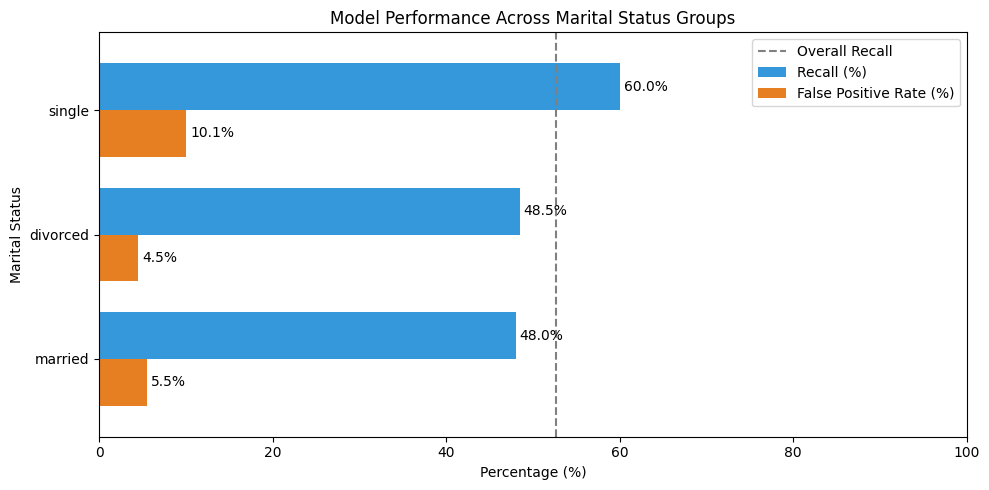

In [96]:
marital_plot = marital_analysis.dropna(
    subset=["Recall (%)"]
).set_index("Group")[
    ["Recall (%)", "False Positive Rate (%)"]
]

ax = marital_plot.plot(
    kind="barh",
    figsize=(10, 5),
    color=["#3498DB", "#E67E22"],
    width=0.75
)

ax.invert_yaxis()

plt.axvline(
    x=recall_score(y_val, lr_opt_pred) * 100,
    color="gray",
    linestyle="--",
    label="Overall Recall"
)

plt.title("Model Performance Across Marital Status Groups")
plt.xlabel("Percentage (%)")
plt.ylabel("Marital Status")
plt.xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.legend()
plt.tight_layout()
plt.show()

### Marital Status Performance Visualization Interpretation

The visualization shows that single customers achieve the highest recall at 60%, exceeding the overall model recall of 52.69%. However, they also have a higher false positive rate than married and divorced customers.

Married and divorced customers have similar recall values, both below the overall model performance.

The unknown marital status category is excluded from the visualization because its recall is undefined.

These results demonstrate that the model's ability to identify potential subscribers varies across marital status groups. However, these differences should be interpreted alongside sample sizes and statistical uncertainty.

Statistical uncertainty: Wilson confidence intervals

### 6.10. Statistical Reliability of Subgroup Performance

Wilson confidence intervals are used to estimate
the uncertainty around subgroup recall, particularly
for groups with small sample sizes.

In [97]:
from statsmodels.stats.proportion import proportion_confint
import numpy as np

def add_recall_confidence_intervals(subgroup_df):

    results = subgroup_df.copy()

    lower_bounds = []
    upper_bounds = []

    for _, row in results.iterrows():

        tp = int(row["True Positives"])
        n = int(row["Actual Subscribers"])

        if n == 0:
            lower_bounds.append(np.nan)
            upper_bounds.append(np.nan)

        else:
            lower, upper = proportion_confint(
                count=tp,
                nobs=n,
                alpha=0.05,
                method="wilson"
            )

            lower_bounds.append(lower * 100)
            upper_bounds.append(upper * 100)

    results["Recall CI Lower (%)"] = lower_bounds
    results["Recall CI Upper (%)"] = upper_bounds

    results["CI Width (%)"] = (
        results["Recall CI Upper (%)"]
        - results["Recall CI Lower (%)"]
    )

    return results

print("Wilson confidence interval function created successfully.")

Wilson confidence interval function created successfully.


### 6.11. Wilson Confidence Intervals Across Customer Groups

In [98]:
age_ci = add_recall_confidence_intervals(age_analysis)

occupation_ci = add_recall_confidence_intervals(job_analysis)

education_ci = add_recall_confidence_intervals(education_analysis)

marital_ci = add_recall_confidence_intervals(marital_analysis)

ci_columns = [
    "Group",
    "Actual Subscribers",
    "Recall (%)",
    "Recall CI Lower (%)",
    "Recall CI Upper (%)",
    "CI Width (%)"
]

for name, df in [
    ("Age Groups", age_ci),
    ("Occupations", occupation_ci),
    ("Education Levels", education_ci),
    ("Marital Status", marital_ci)
]:
    print(f"\n{name}")
    display(df[ci_columns].round(2))


Age Groups


,Group,Actual Subscribers,Recall (%),Recall CI Lower (%),Recall CI Upper (%),CI Width (%)
0,Under 25,58,75.86,63.47,85.04,21.57
1,25-34,351,49.86,44.66,55.06,10.40
2,35-44,228,42.98,36.73,49.47,12.75
3,45-54,141,50.35,42.20,58.49,16.29
4,55-64,89,51.69,41.45,61.78,20.33
5,65+,61,90.16,80.16,95.41,15.26



Occupations


,Group,Actual Subscribers,Recall (%),Recall CI Lower (%),Recall CI Upper (%),CI Width (%)
0,unknown,5,100.00,56.55,100.00,43.45
1,student,57,84.21,72.64,91.46,18.83
2,retired,80,80.00,69.95,87.30,17.34
3,unemployed,27,62.96,44.23,78.47,34.24
4,housemaid,16,62.50,38.64,81.52,42.88
5,admin.,299,60.54,54.89,65.91,11.01
6,management,60,53.33,40.89,65.37,24.48
7,technician,138,47.83,39.66,56.11,16.44
8,self-employed,36,33.33,20.21,49.67,29.45
9,services,65,29.23,19.58,41.20,21.61



Education Levels


,Group,Actual Subscribers,Recall (%),Recall CI Lower (%),Recall CI Upper (%),CI Width (%)
0,unknown,41,65.85,50.55,78.44,27.89
1,university.degree,341,59.53,54.24,64.61,10.36
2,professional.course,123,54.47,45.67,63.00,17.34
3,basic.4y,82,51.22,40.59,61.74,21.15
4,high.school,210,49.52,42.83,56.23,13.40
5,basic.6y,36,41.67,27.14,57.80,30.66
6,basic.9y,95,32.63,24.04,42.57,18.54
7,illiterate,0,NaN,NaN,NaN,NaN



Marital Status


,Group,Actual Subscribers,Recall (%),Recall CI Lower (%),Recall CI Upper (%),CI Width (%)
0,single,360,60.00,54.86,64.93,10.07
1,divorced,97,48.45,38.76,58.27,19.51
2,married,471,47.98,43.51,52.49,8.99
3,unknown,0,NaN,NaN,NaN,NaN


### Wilson Confidence Interval Analysis Interpretation

The Wilson confidence intervals provide additional information about the reliability of subgroup recall estimates.

The age analysis shows a substantial difference between customers aged 65 and above and those aged 35–44. The occupation analysis also reveals important differences, particularly between students, retired customers, blue-collar workers and entrepreneurs.

Although the unknown occupation category achieves 100% recall, its wide confidence interval reflects the small number of actual subscribers. This demonstrates that high observed performance does not necessarily indicate a reliable estimate.

For education levels, university graduates achieve higher recall and a more precise estimate than several basic education categories. Regarding marital status, single customers achieve higher observed recall than married customers.

Categories without actual subscribers have undefined recall and confidence intervals.

Overall, the results highlight the importance of combining performance metrics with statistical uncertainty. These confidence intervals provide descriptive evidence of subgroup differences but do not constitute a formal hypothesis test or establish discrimination.

### 6.12. Visualization of Subgroup Recall Confidence Intervals

In [99]:
def plot_recall_confidence_intervals(df, title):

    plot_df = df.dropna(
        subset=[
            "Recall (%)",
            "Recall CI Lower (%)",
            "Recall CI Upper (%)"
        ]
    ).copy()

    recall = plot_df["Recall (%)"].to_numpy()

    lower_error = (
        recall - plot_df["Recall CI Lower (%)"].to_numpy()
    )

    upper_error = (
        plot_df["Recall CI Upper (%)"].to_numpy() - recall
    )

    errors = np.maximum(
        0,
        np.array([lower_error, upper_error])
    )

    fig, ax = plt.subplots(
        figsize=(11, max(4, len(plot_df) * 0.6))
    )

    ax.errorbar(
        recall,
        plot_df["Group"],
        xerr=errors,
        fmt="o",
        color="#3498DB",
        ecolor="#3498DB",
        capsize=5,
        markersize=7,
        label="Recall with 95% Wilson CI"
    )

    ax.axvline(
        recall_score(y_val, lr_opt_pred) * 100,
        color="gray",
        linestyle="--",
        label="Overall Recall"
    )

    ax.invert_yaxis()
    ax.set_xlim(0, 105)
    ax.set_xlabel("Recall (%)")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

print("Confidence interval visualization function created successfully.")

Confidence interval visualization function created successfully.


Generate confidence interval visualizations

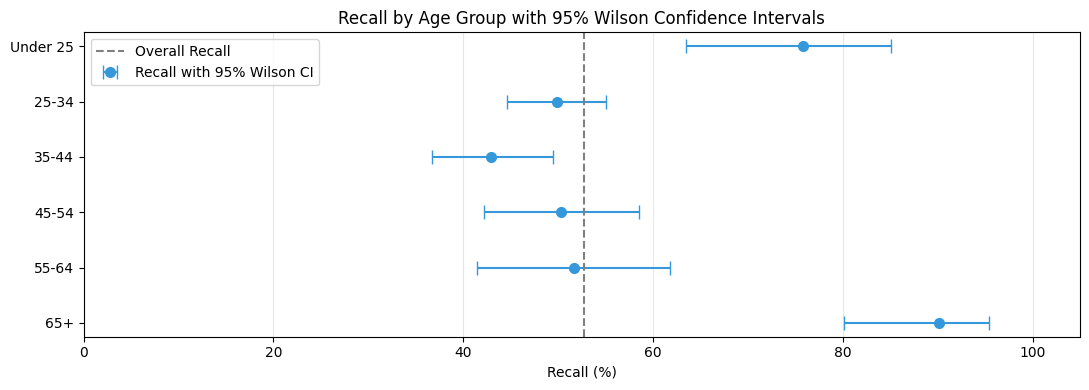

In [100]:
plot_recall_confidence_intervals(
    age_ci,
    "Recall by Age Group with 95% Wilson Confidence Intervals"
)

### Interpretation

The confidence intervals show that the model performs differently
across age groups. Customers aged 65 and above have the highest
recall (90.16%), followed by customers under 25 (75.86%).
Both confidence intervals are entirely above the overall recall
of 52.69%.

In contrast, customers aged 35–44 have a recall of 42.98%,
with a confidence interval between 36.73% and 49.47%.
This suggests that the model has more difficulty identifying
subscribers in this age group.

The remaining age groups have confidence intervals that overlap
the overall recall reference. These results suggest that age-related
performance differences deserve further investigation.

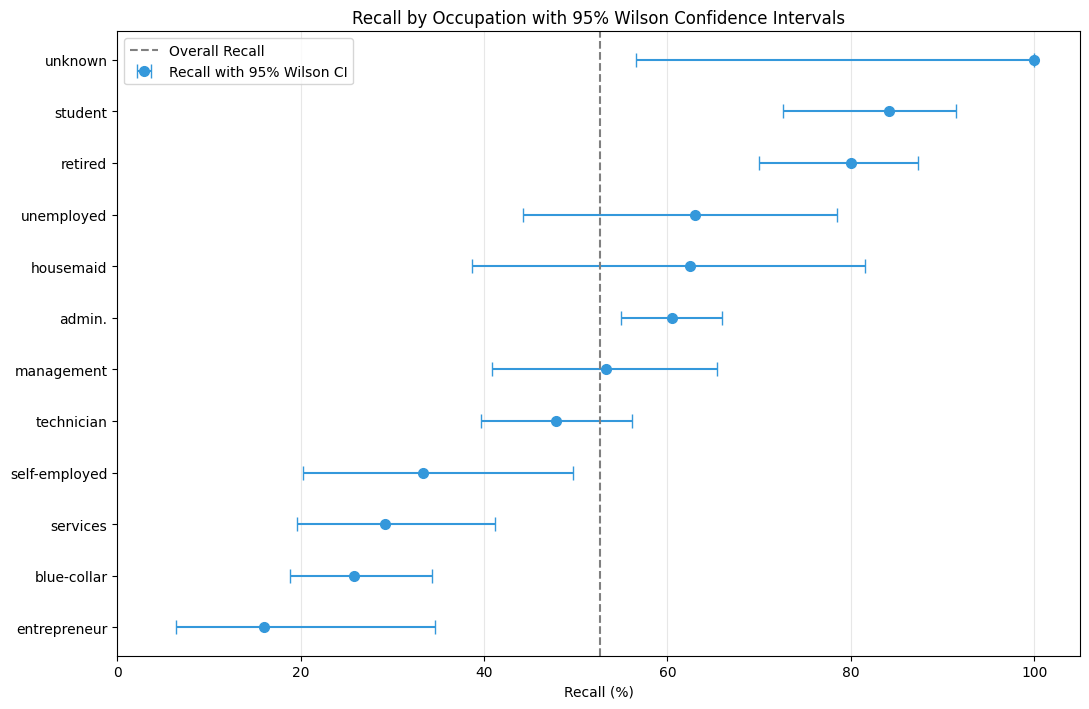

In [101]:
plot_recall_confidence_intervals(
    occupation_ci,
    "Recall by Occupation with 95% Wilson Confidence Intervals"
)

### Interpretation

The model shows considerable differences in recall across
occupations. Students and retired customers achieve high recall
values of 84.21% and 80.00%, respectively.

In contrast, entrepreneurs, blue-collar workers, service workers
and self-employed customers have confidence intervals entirely
below the overall recall reference.

Although the unknown occupation category achieves 100% recall,
this result is based on only five actual subscribers. Its wide
confidence interval (56.55%–100%) indicates substantial uncertainty.

These findings show why subgroup sample sizes should be considered
before drawing conclusions about model performance.

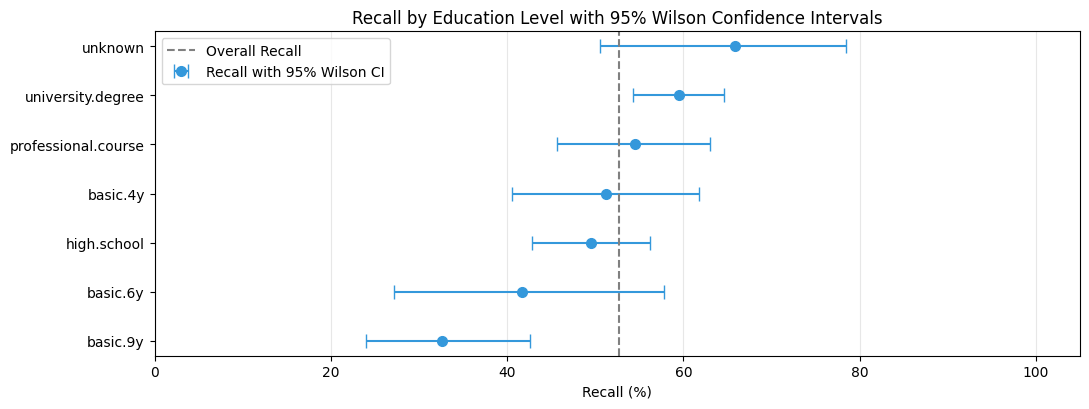

In [102]:
plot_recall_confidence_intervals(
    education_ci,
    "Recall by Education Level with 95% Wilson Confidence Intervals"
)

### Interpretation

Customers with a university degree achieve a recall of 59.53%,
with a relatively narrow confidence interval between 54.24%
and 64.61%.

In comparison, customers in the basic.9y education category
have a recall of only 32.63%, with a confidence interval
between 24.04% and 42.57%.

The unknown education category has the highest observed recall
but also a wider confidence interval, making its estimate
less precise.

The illiterate category is excluded from the visualization
because it contains no actual subscribers in the validation set,
making recall and its confidence interval undefined.

Overall, the results suggest that the model identifies subscribers
more successfully in some education groups than in others.

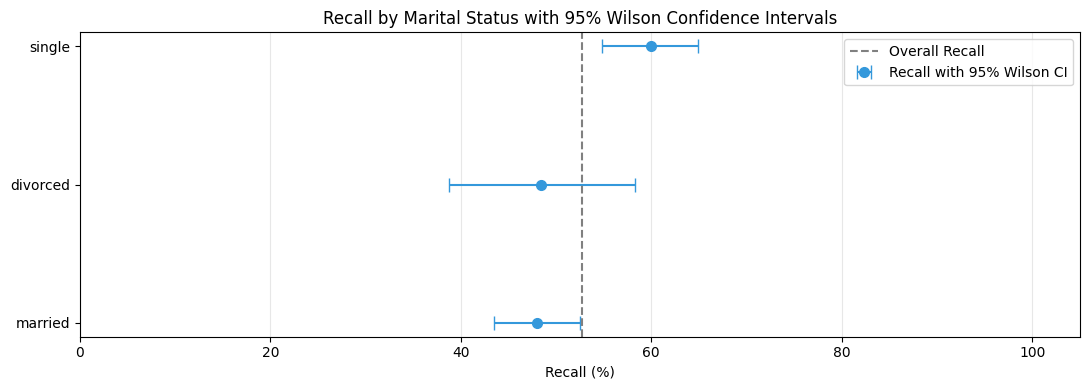

In [103]:
plot_recall_confidence_intervals(
    marital_ci,
    "Recall by Marital Status with 95% Wilson Confidence Intervals"
)

### Interpretation

Single customers achieve the highest recall (60.00%), with
a confidence interval between 54.86% and 64.93%.

Married customers have a lower recall of 47.98%, while divorced
customers achieve 48.45%.

The divorced category has a wider confidence interval because
it contains fewer actual subscribers, resulting in greater
uncertainty.

The unknown marital status category is excluded because no
actual subscribers are present in this subgroup.

These results suggest that the model identifies single
subscribers more successfully than married or divorced
subscribers in the validation dataset.

### Overall Subgroup Analysis Conclusion

The subgroup analysis reveals that the optimized Logistic
Regression model does not perform equally across all customer
groups.

Differences in recall and false positive rates were observed
across age, occupation, education and marital status.

The Wilson confidence intervals provide additional information
about the uncertainty of these estimates, particularly for
groups with a limited number of actual subscribers.

From a business perspective, these differences could lead to
missed subscription opportunities or unnecessary customer contacts.

However, these results are exploratory and based on the validation
dataset. Comparing subgroup confidence intervals with the overall
recall is not a formal statistical significance test, and the
observed differences do not establish discrimination or causality.

Further evaluation should be conducted on the independent test
set after final model selection and threshold optimization.

Customer Targeting and Campaign Efficiency

## 11. Customer Targeting and Campaign Efficiency

This section evaluates how predicted subscription probabilities
can be used to prioritize customers during a marketing campaign.

Instead of contacting every customer, the bank could focus on
customers with the highest predicted probability of subscribing.

The objective is to evaluate how many actual subscribers can
be identified while reducing the number of customer contacts.

In [104]:
targeting_df = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Probability": lr_pipeline.predict_proba(X_val)[:, 1]
})

targeting_df = targeting_df.sort_values(
    "Probability",
    ascending=False
).reset_index(drop=True)

targeting_df["Rank"] = np.arange(
    1, len(targeting_df) + 1
)

targeting_df["Cumulative_Subscribers"] = (
    targeting_df["Actual"].cumsum()
)

targeting_df["Population_Percentage"] = (
    targeting_df["Rank"] / len(targeting_df) * 100
)

targeting_df["Subscribers_Captured_Percentage"] = (
    targeting_df["Cumulative_Subscribers"]
    / targeting_df["Actual"].sum() * 100
)

targeting_df.head(10)

,Actual,Probability,Rank,Cumulative_Subscribers,Population_Percentage,Subscribers_Captured_Percentage
0,1,0.889444,1,1,0.012143,0.107759
1,1,0.885629,2,2,0.024287,0.215517
2,1,0.885362,3,3,0.036430,0.323276
3,1,0.882573,4,4,0.048573,0.431034
4,1,0.879767,5,5,0.060716,0.538793
5,1,0.876668,6,6,0.072860,0.646552
6,1,0.874482,7,7,0.085003,0.754310
7,1,0.870586,8,8,0.097146,0.862069
8,0,0.868035,9,8,0.109290,0.862069
9,1,0.866614,10,9,0.121433,0.969828


### Interpretation

Customers are ranked from the highest to the lowest predicted
subscription probability.

Among the top 10 customers, nine are actual subscribers.
This suggests that Logistic Regression can identify promising
customers and prioritize them for marketing campaigns.

However, a larger-scale evaluation is necessary to determine
the effectiveness of this targeting strategy.

Cumulative Gains Curve

### 11.2 Cumulative Gains Curve

The cumulative gains curve compares model-based customer
targeting with random customer selection.

A curve above the random baseline indicates that the model
can identify subscribers more efficiently than random targeting.

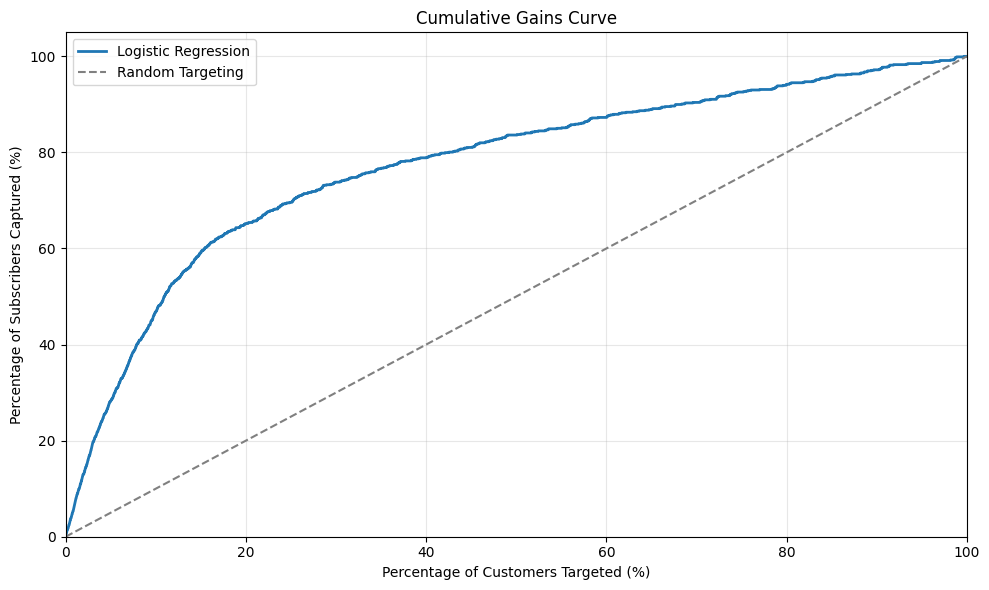

In [105]:
plt.figure(figsize=(10, 6))

plt.plot(
    np.r_[0, targeting_df["Population_Percentage"]],
    np.r_[0, targeting_df["Subscribers_Captured_Percentage"]],
    label="Logistic Regression",
    linewidth=2
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Random Targeting"
)

plt.xlabel("Percentage of Customers Targeted (%)")
plt.ylabel("Percentage of Subscribers Captured (%)")
plt.title("Cumulative Gains Curve")

plt.xlim(0, 100)
plt.ylim(0, 105)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

The cumulative gains curve shows that Logistic Regression
performs considerably better than random customer targeting.

By targeting approximately 20% of customers with the highest
predicted subscription probabilities, the model identifies
around 65% of actual subscribers in the validation dataset.

In comparison, random targeting would identify approximately
20% of subscribers on average.

This suggests that the bank could reduce unnecessary customer
contacts while still identifying a large proportion of
potential subscribers.

However, these results are based on historical validation
data and do not guarantee the same performance in future
marketing campaigns.

### 11.3 Lift Curve

The lift curve measures the improvement of model-based
customer targeting compared with random selection.

A lift greater than 1 indicates that the model identifies
subscribers more efficiently than random targeting.

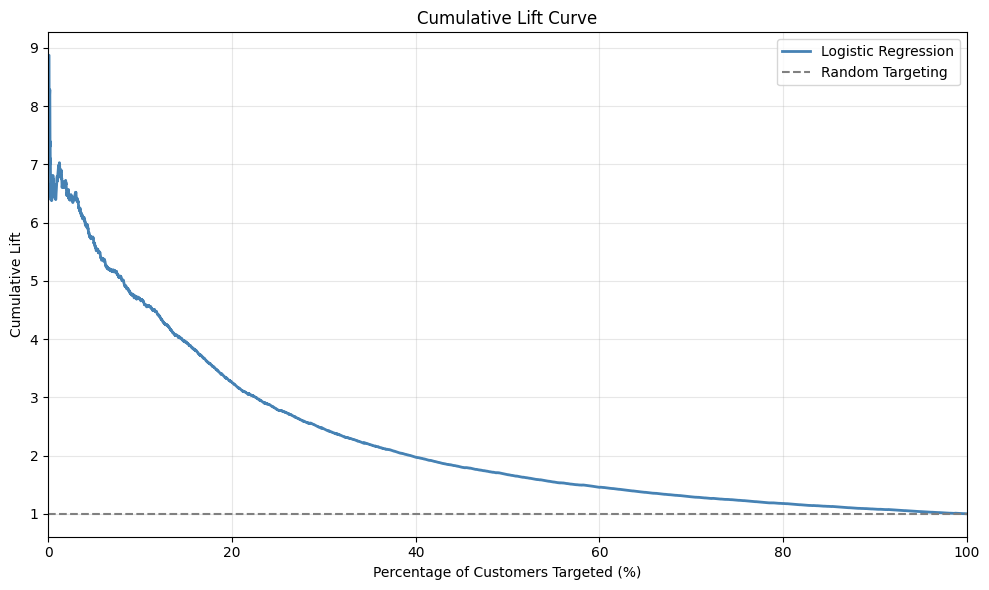

In [106]:
targeting_df["Lift"] = (
    targeting_df["Subscribers_Captured_Percentage"]
    / targeting_df["Population_Percentage"]
)

plt.figure(figsize=(10, 6))

plt.plot(
    targeting_df["Population_Percentage"],
    targeting_df["Lift"],
    color="steelblue",
    linewidth=2,
    label="Logistic Regression"
)

plt.axhline(
    y=1,
    color="gray",
    linestyle="--",
    label="Random Targeting"
)

plt.xlabel("Percentage of Customers Targeted (%)")
plt.ylabel("Cumulative Lift")
plt.title("Cumulative Lift Curve")

plt.xlim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Top-K Customer Targeting Analysis**

### Interpretation

The cumulative lift curve shows that Logistic Regression
is more effective than random customer targeting.

The lift is particularly high when targeting a small
percentage of customers. As more customers are included,
the lift gradually decreases and approaches 1.

This suggests that the model is especially useful when
the bank has a limited marketing budget and needs to
prioritize customers.

### 11.4 Top-K Customer Targeting Analysis

This analysis evaluates the effectiveness of targeting
different percentages of customers based on their predicted
subscription probabilities.

The objective is to compare subscriber coverage, targeting
precision and lift for different campaign sizes.

In [107]:
targeting_results = []

total_customers = len(targeting_df)
total_subscribers = targeting_df["Actual"].sum()

for percentage in [5, 10, 20, 30, 50, 100]:

    k = int(np.ceil(total_customers * percentage / 100))

    selected = targeting_df.head(k)

    captured = selected["Actual"].sum()

    actual_percentage = k / total_customers * 100
    recall = captured / total_subscribers * 100
    precision = captured / k * 100
    lift = recall / actual_percentage

    targeting_results.append({
        "Targeting Budget (%)": percentage,
        "Customers Contacted": k,
        "Subscribers Captured": captured,
        "Subscribers Captured (%)": recall,
        "Precision (%)": precision,
        "Lift": lift,
        "Contacts Avoided": total_customers - k
    })

top_k_df = pd.DataFrame(targeting_results)

top_k_df.round(2)

,Targeting Budget (%),Customers Contacted,Subscribers Captured,Subscribers Captured (%),Precision (%),Lift,Contacts Avoided
0,5,412,262,28.23,63.59,5.64,7823
1,10,824,435,46.88,52.79,4.68,7411
2,20,1647,605,65.19,36.73,3.26,6588
3,30,2471,685,73.81,27.72,2.46,5764
4,50,4118,776,83.62,18.84,1.67,4117
5,100,8235,928,100.00,11.27,1.00,0


### Interpretation

The Top-K analysis confirms that Logistic Regression can
improve customer targeting efficiency.

By targeting only 10% of customers, the model identifies
46.88% of actual subscribers, achieving a lift of 4.68.

When targeting 20% of customers, the model identifies
605 out of 928 actual subscribers while avoiding 6,588
customer contacts compared with contacting everyone.

As the targeting budget increases, subscriber coverage
improves, but precision and lift gradually decrease.

The 20% targeting scenario illustrates a useful balance
between subscriber coverage and campaign size. However,
the optimal budget depends on actual business costs,
expected revenue and available resources.

Final Conclusion and Limitations

## 12. Final Conclusion and Limitations

### Main Findings

This notebook evaluated the performance of the baseline
models from both statistical and business perspectives.

Logistic Regression achieved a ROC-AUC of 0.8081,
demonstrating better discrimination than the Dummy
Classifier.

Threshold optimization improved recall from 22.09%
to 52.69% and F1-score from 0.3350 to 0.5156,
although it also increased false positives.

The business cost sensitivity analysis demonstrated
that the preferred classification strategy depends
on the relative costs of false positives and false
negatives.

The subgroup analysis revealed performance differences
across age, occupation, education and marital status.
Wilson confidence intervals helped assess the
uncertainty of these estimates.

Finally, the customer targeting analysis showed that
contacting only 20% of customers could identify 65.19%
of actual subscribers in the validation dataset.

### Limitations

- All current results are based on the validation set.
- The classification threshold was selected using
  validation data, so its performance may be optimistic.
- Business costs were hypothetical rather than obtained
  from an actual bank.
- Some demographic subgroups contain limited observations.
- Subgroup differences do not establish discrimination
  or causality.
- Historical subscription outcomes do not guarantee
  future campaign performance.
- Alternative and ensemble models have not yet been
  integrated into this comparison.

### Future Work

The next stage will integrate the tuned and ensemble
models developed by the team into the comparison framework.

Once the final model and decision strategy are selected,
performance will be evaluated on the independent test set.